# One set of J++ rules, five architectures

<a href="https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jpp-kola/examples/methods/jpp_lens_architectures_colab.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**The J++ lens's LRP rules are written once as TorchLens rules that pick operations by name and module, and the same rule list runs on five small language models, four transformers and a state-space model; covering Gemma 3 and GPT-2 took three more rule entries.**

The J++ lens (Kola Ayonrinde and Jack Lindsey, [LessWrong, October 2026](https://www.lesswrong.com/posts/nc9dHfcB22JdMzGbr/j-lens-jacobian-filtering-enables-more-faithful-workspace); [code](https://github.com/safety-research/jpp_lens)) reads an intermediate activation as the tokens the model is disposed to say. Like the Jacobian lens (J-lens) of [Gurnee et al. (2026)](https://transformer-circuits.pub/2026/workspace/index.html), it carries the activation to the last layer with one matrix per layer and reads it with the model's own unembedding. J++ estimates that matrix differently: it clusters the activations, fits one "expert" Jacobian per cluster and combines the experts with learned weights (Jacobian Filtering); it computes every Jacobian through a Layer-wise Relevance Propagation backward pass (LRP); and it ranks only tokens that contain a letter or digit (Readout Filtering).

The LRP backward pass is a short list of rules that leave every forward value unchanged and only change gradients. In TorchLens each rule is one `tl.when(selector, edit)`, and the selector names the operation it edits (`rsqrt`, `silu`, the `mul` inside a gated MLP), so a rule follows the operation, not the model. On a new architecture the selectors still need checking (which modules they match, how many operations each rule edits); the notebook asserts the expected counts for these five models. It runs one rule set on five models:

| Model | Kind | What the rules meet |
|---|---|---|
| Qwen2.5-0.5B | transformer | RMSNorm, SiLU-gated MLP: the post's three rules, as written |
| SmolLM2-135M | transformer (Llama family) | the same ops: the rules run unchanged |
| Gemma-3-270m | transformer | RMSNorm, but a GELU-gated MLP: one more rule entry |
| Mamba-130m | state-space model | RMSNorm, and no MLP: the RMSNorm rule fires; the selective scan has no rule |
| GPT-2 small | transformer | LayerNorm and an ungated GELU MLP: two more rule entries |

For each model the notebook checks that the rules change gradients and not values, counts the operations each rule edited, and draws one block with those operations marked. It then fits the J-lens, the R-lens (the pooled LRP Jacobian) and the J++ lens at a small scale and scores them on the post's five readout tasks next to the logit lens.

**Runtime:** 21 minutes on an RTX 2080 Ti GPU for the stored run, and 11 minutes for an earlier version of the notebook on newer libraries (transformers 5.22, torch 2.14). On a free Colab T4 GPU (Runtime > Change runtime type > T4 GPU), expect roughly 15 to 25 minutes (an estimate, not measured on a T4; if a T4 runs out of memory, set `CHUNK = 32` in the setup cell). Without a GPU the notebook runs a much smaller fit, and its numbers only show that the code runs; in separate test runs that path took about 2.5 minutes for SmolLM2-135M, Mamba's checks and GPT-2 on a two-core Mac (the full set of models was not timed on a CPU).

In [1]:
# Colab already has torch, transformers, scikit-learn, pandas and matplotlib.
import shutil
from importlib.metadata import PackageNotFoundError, version


def have(package, floor):
    try:
        return tuple(int(p) for p in version(package).split(".")[: len(floor)]) >= floor
    except (PackageNotFoundError, ValueError):
        return False


if not (
    have("torchlens", (3, 0, 3)) and have("transformers", (4, 56)) and have("datasets", (2, 0))
):
    %pip install -q "torchlens>=3.0.3" "transformers>=4.56" datasets  # 4.56 is the first with from_pretrained(dtype=)

if shutil.which("dot") is None:  # Graphviz draws the block diagrams; Colab images usually have it
    !apt-get -qq install -y graphviz > /dev/null

## Setup

The models load in float32 from the Hugging Face Hub, one at a time (about 2.5 GB of downloads in all). Gemma-3-270m loads from `unsloth/gemma-3-270m`, an ungated copy whose weight file is byte-identical to `google/gemma-3-270m` (same SHA-256), so no Hugging Face token is needed; the weights remain under the Gemma terms of use.

The stored outputs come from a run with transformers 4.57.6 and torch 2.5.1. An earlier version of the notebook on transformers 5.22 and torch 2.14 gave readout scores up to 5.3 points different; those runs differ in code as well as libraries, so they do not isolate the cause, and a run on other library versions may differ too.

On a GPU the fit uses 8 sequences per model. Without a GPU it shrinks to one sequence and a few optimiser steps. Then most or all expert Jacobians fall back to the pooled one (the results table counts them), so J++ reads out much as the R-lens does: treat CPU numbers as a test of the code, not a result.

In [2]:
import base64
import functools
import gc
import json
import operator
import time
import urllib.request
import warnings
from types import SimpleNamespace

import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from IPython.display import HTML, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from transformers import AutoModelForCausalLM, AutoTokenizer

import torchlens as tl

%config InlineBackend.figure_format = "retina"
transformers.logging.set_verbosity_error()  # Mamba without its CUDA kernels says so at length
warnings.filterwarnings("ignore", message=".*fast path.*")
# transformers 4.x builds attention masks with vmap, which TorchLens records as one boundary op per capture
warnings.filterwarnings("ignore", message="TorchLens captured a vmap transform")
huggingface_hub.utils.disable_progress_bars()
# torchlens 3.0.3 warns once about the size of a view-mode trace even with save_budget=None; later releases do not.
tl.errors.quiet("capture_memory_threshold_exceeded")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU = DEVICE == "cuda"
BIG_GPU = GPU and torch.cuda.get_device_properties(0).total_memory > 14 * 2**30
SEQ_LEN, SKIP = (
    128,
    16,
)  # WikiText sequences of 128 tokens; drop the first 16 positions and the last (as the post)
E = 8  # expert Jacobians per layer (as the post)
N_FIT = 8 if GPU else 1  # sequences for the Jacobians (post: 64)
N_CLUSTER = 256 if GPU else 16  # sequences for the k-means routers (post: 1,000)
BATCH = 4 if GPU else 1  # sequences per traced forward pass
CHUNK = 64 if BIG_GPU or not GPU else 32  # Jacobian rows per batched backward pass (a memory knob)
WEIGHT_STEPS = 200 if GPU else 10  # Adam steps for the J++ weights (post: 200)
FIT_MAMBA = False  # see the note in "Fit and score every model"
SEED = 0

MODELS = {
    "Qwen2.5-0.5B": "Qwen/Qwen2.5-0.5B",
    "SmolLM2-135M": "HuggingFaceTB/SmolLM2-135M",
    "Gemma-3-270m": "unsloth/gemma-3-270m",
    "Mamba-130m": "state-spaces/mamba-130m-hf",
    "GPT-2 small": "openai-community/gpt2",
}
COLORS = {"Logit lens": "#AAAAAA", "J-lens": "#4D4D4D", "R-lens": "#D97B00", "J++ lens": "#0072B2"}


class Model:
    """One causal LM with the handles a lens needs: its blocks, its final norm and its unembedding."""

    def __init__(self, name):
        self.name, self.repo = name, MODELS[name]
        self.tok = AutoTokenizer.from_pretrained(self.repo)
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        extra = {} if "mamba" in self.repo else {"attn_implementation": "eager"}
        self.model = AutoModelForCausalLM.from_pretrained(self.repo, dtype=torch.float32, **extra)
        self.model.config.use_cache = False
        self.model.eval().to(DEVICE)
        n = self.model.config.num_hidden_layers
        stack = next(
            name
            for name, m in self.model.named_modules()
            if isinstance(m, torch.nn.ModuleList) and len(m) == n
        )
        self.blocks = [f"{stack}.{i}" for i in range(n)]
        # the final norm sits on the decoder; on transformers 4.x Gemma 3's base_model is the whole model
        decoders = [self.model.base_model, getattr(self.model, "model", None)]
        self.norm = next(
            getattr(d, a)
            for d in decoders
            if d is not None
            for a in ("norm", "norm_f", "ln_f")
            if hasattr(d, a)
        )
        self.layers = [
            n * k // 8 for k in range(1, 8)
        ]  # seven readout layers, as the released code
        self.sources = [self.blocks[i] for i in self.layers]
        self.d = self.model.config.hidden_size

    def unembed(self, x):
        """The model's own readout: final norm, then the LM head."""
        return self.model.lm_head(self.norm(x))


def release():
    """Return freed memory (call after `del`-ing a model or a trace) before the next one loads."""
    gc.collect()
    if GPU:
        torch.cuda.empty_cache()


def first(x):
    """A block's output tensor (some blocks return a tuple)."""
    return x[0] if isinstance(x, (tuple, list)) else x


t_start = time.time()
print(
    f"torch {torch.__version__}, transformers {transformers.__version__}, torchlens {tl.__version__}"
)
print(f"device: {torch.cuda.get_device_name(0) if GPU else 'CPU'}")

site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.5.1+cu121, transformers 4.57.6, torchlens 3.0.3
device: NVIDIA GeForce RTX 2080 Ti


## The rules, written once

The post's LRP rules (its Table 5, and `lrp/lrp.py` in the released code), each as one TorchLens rule. A rule's selector says *which* operations it edits; its edit returns the same value with a different autograd graph, so forward values are unchanged and gradients follow the rule.

- **LN rule**: hold the RMSNorm scale `rsqrt(mean(x^2) + eps)` constant. The released code leaves the norms inside attention (Gemma's query and key norms) on the plain gradient, so the selector excludes attention modules.
- **Identity rule**: treat the gated MLP's activation as linear in its input: `silu(z) = z * sigmoid(z)` with the sigmoid held constant.
- **Half rule**: send half the gradient through the gated MLP's product `act(gate(x)) * up(x)`.

Everything else keeps its plain gradient, attention included. Three lines extend the set to ops Qwen never calls; each follows the released code or the paper the post builds on:

- **GELU identity rule** (Gemma 3): `gelu(z) = z * Phi(z)` with the gate `Phi` held constant. The released code applies exactly this to Gemma 4's GELU-tanh MLP ("RelP's GELU / SiLU identity rule").
- **LayerNorm LN rule** (GPT-2): hold `1 / std(x)` constant, the LN rule in its original form (Ali et al. 2022, the rule the post's RMSNorm version comes from).
- **tanh-GELU identity rule** (GPT-2): GPT-2's GELU is written out as `0.5 * z * (1 + tanh(...))`; holding the `tanh` constant holds the gate `0.5 * (1 + tanh(...))` constant, which is the identity rule again.

The selectors name module contexts with `tl.in_module`; `modules_of` builds one selector for every module of a kind (every `...MLP`, every `...Attention`).

In [3]:
def modules_of(model, kind, gated=False):
    """One selector for every module whose class name ends with `kind`; None if the model has none."""
    names = [
        name
        for name, m in model.named_modules()
        if type(m).__name__.endswith(kind) and (not gated or hasattr(m, "up_proj"))
    ]
    return functools.reduce(operator.or_, map(tl.in_module, names)) if names else None


def hold_constant(out, *, ctx):
    """The value, with no gradient through it (RMSNorm's rsqrt; the tanh inside GPT-2's GELU)."""
    return out.detach()


def silu_identity(out, *, ctx):
    """silu(z) = z * sigmoid(z), with the sigmoid held constant."""
    z = ctx.args[0]
    return z * torch.sigmoid(z).detach()


def half(out, *, ctx):
    """Half of the gradient through the gated-MLP product."""
    return 0.5 * out + 0.5 * out.detach()


def gelu_identity(out, *, ctx):
    """gelu(z) = z * Phi(z), with the gate Phi (or its tanh approximation) held constant."""
    z = ctx.args[0]
    if ctx.kwargs.get("approximate", "none") == "tanh":
        gate = 0.5 * (1 + torch.tanh((2 / torch.pi) ** 0.5 * (z + 0.044715 * z**3)))
    else:
        gate = 0.5 * (1 + torch.erf(z / 2**0.5))
    return z * gate.detach()


def layernorm_identity(out, *, ctx):
    """LayerNorm with 1 / std(x) held constant."""
    x, _, weight, bias, eps = ctx.args[:5]
    scale = torch.rsqrt(x.var(-1, keepdim=True, unbiased=False) + eps).detach()
    return (x - x.mean(-1, keepdim=True)) * scale * weight + bias


def lrp_rules(model):
    """The J++ LRP rules for one model: {rule: (selector, edit)}; a rule whose module context the model lacks is left out."""
    attention = modules_of(model, "Attention")
    mlp = modules_of(model, "MLP")
    gated_mlp = modules_of(model, "MLP", gated=True)
    rules = {
        # the post's three rules
        "LN rule (RMSNorm)": (
            tl.func("rsqrt") if attention is None else tl.func("rsqrt") - attention,
            hold_constant,
        ),
        "identity rule (SiLU)": (None if mlp is None else tl.func("silu") & mlp, silu_identity),
        "half rule (gated MLP)": (None if gated_mlp is None else tl.func("mul") & gated_mlp, half),
        # one line added for Gemma 3
        "identity rule (GELU)": (None if mlp is None else tl.func("gelu") & mlp, gelu_identity),
        # two lines added for GPT-2
        "LN rule (LayerNorm)": (tl.func("layer_norm"), layernorm_identity),
        "identity rule (tanh GELU)": (
            None if mlp is None else tl.func("tanh") & mlp,
            hold_constant,
        ),
    }
    return {rule: (sel, edit) for rule, (sel, edit) in rules.items() if sel is not None}


def as_recipe(rules):
    """All rules as one TorchLens recipe: `&` merges `tl.when` clauses."""
    return functools.reduce(operator.and_, (tl.when(sel, edit) for sel, edit in rules.values()))


def lrp_trace(m, ids, rules, **capture):
    """A trace of one forward pass under the rules (none: a plain trace); a rule that matches no op is recorded, not warned about."""
    options = tl.options.CaptureOptions(**capture) if capture else None
    if not rules:
        return tl.trace(m.model, ids, capture=options)
    return tl.trace(
        m.model, ids, capture=options, intervene=as_recipe(rules), on_zero_fire="disclose"
    )

Each edit is checked on its own before any model runs: it must return the same value as the operation it replaces and the derivative its rule prescribes (float64, random inputs).

In [4]:
def edit_check(edit, value, args, kwargs, reference, expected_grad):
    """Run one edit on a fresh input; compare its value and its input gradient with the rule's."""
    z = args[0]
    out = edit(value(z), ctx=SimpleNamespace(args=args, kwargs=kwargs))
    (grad,) = torch.autograd.grad(out.mul(GRAD_PROBE).sum(), z)
    return torch.allclose(out, reference(z)), torch.allclose(grad, expected_grad(z))


torch.manual_seed(SEED)
GRAD_PROBE = torch.randn(4, 6, dtype=torch.float64)  # a random cotangent
w, b = torch.randn(6, dtype=torch.float64), torch.randn(6, dtype=torch.float64)
up = torch.randn(4, 6, dtype=torch.float64)
x = lambda: torch.randn(4, 6, dtype=torch.float64, requires_grad=True)  # noqa: E731
phi = lambda z: 0.5 * (1 + torch.erf(z / 2**0.5))  # noqa: E731
tanh_gate = lambda z: 0.5 * (1 + torch.tanh((2 / torch.pi) ** 0.5 * (z + 0.044715 * z**3)))  # noqa: E731
inv_rms = lambda z: torch.rsqrt(z.pow(2).mean(-1, keepdim=True) + 1e-6)  # noqa: E731
inv_std = lambda z: torch.rsqrt(z.var(-1, keepdim=True, unbiased=False) + 1e-5)  # noqa: E731
z0 = x()
checks = {
    # hold the RMSNorm scale constant: d/dz [z * s(z)] = s(z) * probe
    "LN rule (RMSNorm)": edit_check(
        lambda out, ctx: ctx.args[0] * hold_constant(out, ctx=ctx),
        inv_rms,
        (z0,),
        {},
        lambda z: z * inv_rms(z),
        lambda z: GRAD_PROBE * inv_rms(z).detach(),
    ),
    "identity rule (SiLU)": edit_check(
        silu_identity, F.silu, (x(),), {}, F.silu, lambda z: GRAD_PROBE * torch.sigmoid(z).detach()
    ),
    "half rule (gated MLP)": edit_check(
        half, lambda z: z * up, (x(),), {}, lambda z: z * up, lambda z: 0.5 * GRAD_PROBE * up
    ),
    "identity rule (GELU)": edit_check(
        gelu_identity, F.gelu, (x(),), {}, F.gelu, lambda z: GRAD_PROBE * phi(z).detach()
    ),
    "identity rule (GELU, tanh form)": edit_check(
        gelu_identity,
        lambda z: F.gelu(z, approximate="tanh"),
        (x(),),
        {"approximate": "tanh"},
        lambda z: F.gelu(z, approximate="tanh"),
        lambda z: GRAD_PROBE * tanh_gate(z).detach(),
    ),
    "LN rule (LayerNorm)": edit_check(
        layernorm_identity,
        lambda z: F.layer_norm(z, (6,), w, b, 1e-5),
        (x(), (6,), w, b, 1e-5),
        {},
        lambda z: F.layer_norm(z, (6,), w, b, 1e-5),
        lambda z: inv_std(z).detach() * (GRAD_PROBE * w - (GRAD_PROBE * w).mean(-1, keepdim=True)),
    ),
}
display(pd.DataFrame(checks, index=["value unchanged", "gradient as the rule says"]).T)
assert all(all(c) for c in checks.values()), "an edit does not do what its rule says"

,value unchanged,gradient as the rule says
LN rule (RMSNorm),True,True
identity rule (SiLU),True,True
half rule (gated MLP),True,True
identity rule (GELU),True,True
"identity rule (GELU, tanh form)",True,True
LN rule (LayerNorm),True,True


## The same rules on five models

Each model runs one short prompt three ways: untraced, traced under the rules, and through live `save_mode="view"` traces with and without the rules. The rules must change gradients and never values, so the cell asserts that the logits under the rules match the untraced model's to float32 round-off, and that the gradient of the top next-token logit with respect to the first readout layer's residual stream does change. Each edit also logs the TorchLens record of the op it edited (`ctx.op`), so the table counts the operations each rule edited in one forward pass, and the cell asserts the expected count for every rule: one LN edit per norm module outside attention (for Gemma 3 this also shows its query and key norms inside attention were left alone, since editing them would add 36), one activation edit per MLP and one half-rule edit per gated MLP. The model-level gradient check is an aggregate smoke test; the per-edit checks above test each rule's derivative. A blank cell means no operation matched that rule.

In [5]:
PROMPT = "The Eiffel Tower is in the city of"
DRAW_PROMPT = (
    "The Eiffel Tower"  # a shorter prompt keeps Mamba's per-position scan small in the drawing
)


def counted(rules, log):
    """The same rules, with each edit also logging the label of the op it edited."""

    def wrap(rule, edit):
        @functools.wraps(edit)
        def logged(out, *, ctx):
            log.setdefault(rule, []).append(ctx.op["label"])
            return edit(out, ctx=ctx)

        return logged

    return {rule: (sel, wrap(rule, edit)) for rule, (sel, edit) in rules.items()}


def norms_outside_attention(model):
    """Norm modules on the residual stream: every ...RMSNorm or ...LayerNorm that is not inside an attention module."""
    attention = [n for n, mod in model.named_modules() if type(mod).__name__.endswith("Attention")]
    return sum(
        type(mod).__name__.endswith(("RMSNorm", "LayerNorm"))
        and not any(n.startswith(a + ".") for a in attention)
        for n, mod in model.named_modules()
    )


def mlp_counts(model):
    """(gated, ungated) MLP modules: each calls one activation, and a gated one also one gate product."""
    mlps = [mod for mod in model.modules() if type(mod).__name__.endswith("MLP")]
    gated = sum(hasattr(mod, "up_proj") for mod in mlps)
    return gated, len(mlps) - gated


def gradient_at_source(m, ids, rules):
    """d(top next-token logit) / d(residual stream at the first readout layer), through a live view-mode trace."""
    trace = lrp_trace(m, ids, rules, save_mode="view", save_budget=None)
    return torch.autograd.grad(trace.output.logits[0, -1].max(), first(trace[m.sources[0]].out))[0]


facts, edited, change, grad_change, norms, mlps = {}, {}, {}, {}, {}, {}
for i, name in enumerate(MODELS):
    m = Model(name)
    ids = m.tok(PROMPT, return_tensors="pt").input_ids.to(DEVICE)
    rules, log = lrp_rules(m.model), {}
    with torch.no_grad():
        reference = m.model(ids).logits  # the untraced model
        under_rules = lrp_trace(
            m, ids, counted(rules, log)
        ).output.logits  # Trace.output: what the model returned
    change[name] = float((reference - under_rules).abs().max() / reference.abs().max())
    plain_grad, lrp_grad = gradient_at_source(m, ids, {}), gradient_at_source(m, ids, rules)
    grad_change[name] = float((plain_grad - lrp_grad).norm() / plain_grad.norm())
    edited[name] = {rule: len(labels) for rule, labels in log.items()}
    norms[name], mlps[name] = norms_outside_attention(m.model), mlp_counts(m.model)
    hits = lambda *rules: sum(edited[name].get(rule, 0) for rule in rules)  # noqa: E731
    assert change[name] < 1e-4, f"{name}: the rules changed the forward pass"
    assert grad_change[name] > 1e-3, f"{name}: the rules left the gradient unchanged"
    assert hits("LN rule (RMSNorm)", "LN rule (LayerNorm)") == norms[name], (
        f"{name}: one LN edit per norm module"
    )
    assert hits("half rule (gated MLP)") == mlps[name][0], (
        f"{name}: one half-rule edit per gated MLP"
    )
    activations = hits("identity rule (SiLU)", "identity rule (GELU)", "identity rule (tanh GELU)")
    assert activations == sum(mlps[name]), f"{name}: one activation edit per MLP"
    # One block, drawn from a trace under the rules: draw() marks the ops an intervention edited.
    # Attention modules and Mamba's mixer are collapsed to one box each, so the norms and the MLP are readable.
    with torch.no_grad():
        short = lrp_trace(
            m, m.tok(DRAW_PROMPT, return_tensors="pt").input_ids.to(DEVICE), lrp_rules(m.model)
        )
    short.draw(
        f"block_{i}.svg",
        module=m.blocks[0],
        file_format="svg",
        collapse_fn=lambda module: module.class_name.endswith(("Attention", "Mixer")),
    )
    facts[name] = {
        "kind": "state-space" if "mamba" in m.repo else "transformer",
        "blocks": len(m.blocks),
        "d_model": m.d,
        "vocabulary": m.model.lm_head.out_features,
        "parameters (M)": round(sum(p.numel() for p in m.model.parameters()) / 1e6),
        "revision": huggingface_hub.model_info(m.repo).sha[:12],
    }
    del m, reference, under_rules, plain_grad, lrp_grad, short
    release()

display(pd.DataFrame(facts))
RULE_ORDER = [
    "LN rule (RMSNorm)",
    "identity rule (SiLU)",
    "half rule (gated MLP)",
    "identity rule (GELU)",
    "LN rule (LayerNorm)",
    "identity rule (tanh GELU)",
]
counts = pd.DataFrame(edited).reindex(RULE_ORDER)
counts = counts.map(lambda v: "" if pd.isna(v) else f"{v:.0f}")
counts.loc["norm modules outside attention"] = [f"{norms[n]}" for n in counts.columns]
counts.loc["MLP modules, gated / ungated"] = [
    f"{mlps[n][0]} / {mlps[n][1]}" for n in counts.columns
]
counts.loc["largest logit change, relative"] = [f"{change[n]:.0e}" for n in counts.columns]
counts.loc["gradient change at the first readout layer, relative"] = [
    f"{grad_change[n]:.2f}" for n in counts.columns
]
display(counts)

,Qwen2.5-0.5B,SmolLM2-135M,Gemma-3-270m,Mamba-130m,GPT-2 small
kind,transformer,transformer,transformer,state-space,transformer
blocks,24,30,18,24,12
d_model,896,576,640,768,768
vocabulary,151936,49152,262144,50280,50257
parameters (M),494,135,268,129,124
revision,060db6499f32,93efa2f097d5,edcf1fe394ee,1e76775f628f,607a30d783df


,Qwen2.5-0.5B,SmolLM2-135M,Gemma-3-270m,Mamba-130m,GPT-2 small
LN rule (RMSNorm),49,61,73,25,
identity rule (SiLU),24,30,,,
half rule (gated MLP),24,30,18,,
identity rule (GELU),,,18,,
LN rule (LayerNorm),,,,,25
identity rule (tanh GELU),,,,,12
norm modules outside attention,49,61,73,25,25
"MLP modules, gated / ungated",24 / 0,30 / 0,18 / 0,0 / 0,0 / 12
"largest logit change, relative",3e-06,2e-06,6e-07,0e+00,4e-07
"gradient change at the first readout layer, relative",0.89,0.89,0.87,1.19,1.80


Qwen2.5 and SmolLM2 have two RMSNorms per block plus the final one, and one SiLU and one gate product per MLP. Gemma 3 has four residual-stream RMSNorms per block (its query and key norms sit inside attention and keep the plain gradient) and calls GELU where Qwen calls SiLU; the one GELU line covers it. Mamba's blocks are an RMSNorm and a mixer: the LN rule edits the RMSNorms and nothing else matches. Mamba has no MLP, and its selective scan, convolution and SiLU gate, for which the post gives no rule, keep the plain gradient (the post's Qwen3.6 has state-space-like Gated DeltaNet layers, and the released code leaves those on the plain gradient too). GPT-2 matches the two lines added for it, and the half rule finds nothing, since GPT-2's MLP is not gated.

One block per model as TorchLens draws it from the trace under the rules, with attention (and Mamba's mixer) collapsed to one box. Purple outlines mark the operations a rule edited, labelled with the edit's name. The drawings are vector images: zoom in to read the labels.

In [6]:
cards = "".join(
    f'<figure style="margin:0 12px 16px 0;display:inline-block;vertical-align:top;width:420px;max-width:100%">'
    f'<figcaption style="font:600 14px sans-serif;margin-bottom:4px">{name}</figcaption>'
    f'<img src="data:image/svg+xml;base64,{base64.b64encode(open(f"block_{i}.svg", "rb").read()).decode()}" style="width:100%"></figure>'
    for i, name in enumerate(MODELS)
)
display(HTML(f"<div>{cards}</div>"))

## Fitting text, routers and expert Jacobians

The fit follows the post and the released code at a smaller size. Per model: WikiText-103 sequences of 128 tokens; k-means routers per readout layer (unit-normalise, 64 principal components, 8 clusters) fitted on the residual stream that `tl.extract` returns; then one traced forward pass per batch with `save_mode="view"`, which keeps the live residual stream so that `torch.autograd.grad` can differentiate the last block's output with respect to it. One backward pass per chunk of output rows gives the Jacobian rows at every source position and readout layer at once. J++ sums them per cluster (the expert Jacobians); the plain average over all positions is the pooled Jacobian. Each model is fitted twice, with the plain backward pass (J-lens) and under the LRP rules (R-lens and J++), and the only difference between the two calls is `intervene=`.

In [7]:
def paragraphs(n, seed):
    """n WikiText-103 paragraphs long enough to give SEQ_LEN tokens with any of the five tokenizers."""
    stream = load_dataset(
        "Salesforce/wikitext", "wikitext-103-raw-v1", split="train", streaming=True
    )
    out = []
    for row in stream.shuffle(seed=seed, buffer_size=20_000):
        if len(row["text"]) > 1200:
            out.append(row["text"])
            if len(out) == n:
                return out


TEXTS = paragraphs(N_FIT + N_CLUSTER + 64, SEED)
KEEP = slice(SKIP, SEQ_LEN - 1)


def sequences(tok, texts, n):
    """The first n of these paragraphs as SEQ_LEN-token sequences."""
    seqs = [ids[:SEQ_LEN] for ids in tok(texts).input_ids if len(ids) >= SEQ_LEN]
    return torch.tensor(seqs[:n])


def fit_routers(m, seqs):
    """One k-means router per readout layer, fitted on the residual stream from tl.extract."""
    acts = [[] for _ in m.sources]
    with torch.no_grad():
        for ids in seqs.split(
            8
        ):  # small batches keep each capture well inside the default save budget
            outs = tl.extract(m.model, ids.to(DEVICE), {block: block for block in m.sources})
            for store, block in zip(acts, m.sources):
                store.append(first(outs[block])[:, KEEP].reshape(-1, m.d).float().cpu())
    return [
        make_pipeline(
            Normalizer(),
            PCA(64, random_state=SEED),
            KMeans(E, n_init=1, max_iter=100, random_state=SEED),
        ).fit(torch.cat(a).numpy())
        for a in acts
    ]


def residual_stream(m, ids, rules=None):
    """One traced forward pass: the live residual stream at the readout layers and after the last block."""
    trace = lrp_trace(
        m, ids, rules, save_mode="view", save_budget=None
    )  # live tensors, kept on purpose
    return [first(trace[block].out) for block in m.sources], first(trace[m.blocks[-1]].out)


def fit_experts(m, routers, seqs, rules=None, batch=BATCH):
    """Per-cluster sums of d h_final / d h_layer, and per-cluster position counts, at every readout layer."""
    sums = torch.zeros(len(m.sources), E, m.d, m.d, device=DEVICE)
    counts = torch.zeros(len(m.sources), E, device=DEVICE)
    for ids in seqs.split(batch):
        sources, final = residual_stream(m, ids.to(DEVICE), rules)
        clusters = [
            F.one_hot(
                torch.as_tensor(
                    r.predict(h[:, KEEP].reshape(-1, m.d).detach().cpu().numpy()), dtype=torch.long
                ),
                E,
            )
            .float()
            .to(DEVICE)
            for r, h in zip(routers, sources)
        ]
        target = final[:, KEEP].sum((0, 1))  # a cotangent at every kept target position
        for start in range(0, m.d, CHUNK):
            rows = torch.eye(m.d, device=DEVICE)[start : start + CHUNK]
            grads = torch.autograd.grad(
                target, sources, grad_outputs=rows, is_grads_batched=True, retain_graph=True
            )
            for i, (grad, onehot) in enumerate(zip(grads, clusters)):
                per_position = grad[:, :, KEEP].reshape(len(rows), -1, m.d)
                sums[i, :, start : start + CHUNK] += torch.einsum(
                    "rpd,pe->erd", per_position, onehot
                )
        counts += torch.stack([c.sum(0) for c in clusters])
        del sources, final, target, grads
        release()
    return sums, counts


def expert_jacobians(sums, counts, min_positions=50):
    """Expert J_i = mean over cluster i's positions (under 50 positions: the pooled J, as the released code), and the pooled J."""
    pooled = sums.sum(1) / counts.sum(1)[:, None, None]
    experts = sums / counts[..., None, None].clamp(min=1)
    return torch.where((counts < min_positions)[..., None, None], pooled[:, None], experts), pooled

## The readout evals and the J++ weights

The post's five latent-variable tasks (data from `anthropics/jacobian-lens` via the J++ repository, Apache-2.0): multihop, multilingual, typo, association and poetry. Each item has a prompt, a readout position (the last prompt token; for poetry the end of the first line) and one or more intermediate variables. An intermediate is read out at a layer if any of its single-token surface forms is in the lens's top 10 there; intermediates with no single-token form in a model's vocabulary are dropped, and an item scores the fraction of its intermediates hit at any of the seven layers. As in the post, multihop, multilingual and poetry items count only when the model answers them correctly, meaning its greedy next token is the answer or the answer's first piece; 20% of each task's items fit the J++ weights and every lens is scored on the rest. Readout Filtering drops tokens with no letter or digit, for every lens.

The J++ weights follow the released code: per layer, one signed weight per expert, fitted on the dev items by Adam on a smooth stand-in for recall@10 (200 steps from three starts, keeping the weights with the best exact dev recall). The logits here go through each model's own final norm, which works for LayerNorm as well as RMSNorm.

In [8]:
EVALS = (
    "https://raw.githubusercontent.com/safety-research/jpp_lens/d7efc0de372e/data/jlens/evaluations"
)
TASKS = ["multihop", "multilingual", "typo", "association", "poetry"]
RAW = [
    (task, item)
    for task in TASKS
    for item in json.load(urllib.request.urlopen(f"{EVALS}/lens-eval-{task}.json"))["items"]
]


def candidates(tok, word):
    forms = {p + w for w in {word, word.capitalize(), word.lower()} for p in ("", " ")}
    return sorted(
        {
            ids[0]
            for ids in (tok(f, add_special_tokens=False).input_ids for f in forms)
            if len(ids) == 1
        }
    )


def eval_items(m):
    """The scored items for one model, each with its residual stream at the readout position, split into dev and test."""
    tok = m.tok
    raw = [
        (t, it, c)
        for t, it in RAW
        if (c := [x for x in (candidates(tok, w) for w in it["intermediates"]) if x])
    ]
    tok.padding_side = "right"  # causal: a real token never attends to the pads after it
    items = []
    for start in range(
        0, len(raw), 8
    ):  # small batches keep each capture inside the default save budget
        group = raw[start : start + 8]
        enc = tok([it["prompt"] for _, it, _ in group], return_tensors="pt", padding=True).to(
            DEVICE
        )
        with torch.no_grad():
            outs = tl.extract(m.model, enc.input_ids, {block: block for block in m.sources})
            resid = torch.stack([first(outs[block]) for block in m.sources], 1)
            logits = m.model(enc.input_ids).logits
        for b, (task, item, cands) in enumerate(group):
            n = int(enc.attention_mask[b].sum())
            pos = (
                n - 1
                if task != "poetry"
                else max(i for i in range(n) if "\n" in tok.decode(enc.input_ids[b, i]))
            )
            target = (
                item.get("target")
                if task in ("multihop", "multilingual")
                else item["intermediates"][0]
                if task == "poetry"
                else None
            )
            word = tok.decode(logits[b, n - 1].argmax()).lstrip()
            correct = target is None or (bool(word) and target.strip().startswith(word))
            items.append(
                {
                    "task": task,
                    "cands": cands,
                    "h": resid[b, :, pos].clone(),
                    "correct": correct,
                    "dev": False,
                }
            )
    rng = np.random.default_rng(SEED)  # the released code's split
    for task in sorted(TASKS):
        members = [it for it in items if it["task"] == task and it["correct"]]
        for j, k in enumerate(rng.permutation(len(members))):
            members[k]["dev"] = j < max(1, int(0.2 * len(members)))
    vocab = m.model.lm_head.out_features
    texts = tok.batch_decode([[i] for i in range(vocab)])
    nonsemantic = torch.tensor([not any(ch.isalnum() for ch in t) for t in texts], device=DEVICE)
    nonsemantic[[c for it in items for cs in it["cands"] for c in cs]] = False
    dev = [it for it in items if it["dev"]]
    test = [it for it in items if it["correct"] and not it["dev"]]
    return dev, test, nonsemantic


def fit_weights(
    m, experts_l, layer, dev, nonsemantic, steps=WEIGHT_STEPS, lr=0.05, temperature=0.1, k=10
):
    """Signed unit-norm weights over one layer's expert Jacobians, fitted on the dev items' recall@k."""
    frozen = [p for p in m.model.parameters() if p.requires_grad]
    for p in frozen:
        p.requires_grad_(
            False
        )  # only the expert weights learn; the head and final norm stay out of autograd
    with torch.no_grad():
        moved = torch.einsum(
            "edk,pk->ped", experts_l, torch.stack([it["h"][layer] for it in dev])
        )  # [P, E, d]
    pairs = [(p, c) for p, it in enumerate(dev) for c in it["cands"]]
    task_of = torch.tensor([TASKS.index(dev[p]["task"]) for p, _ in pairs], device=DEVICE)
    pad = max(len(c) for _, c in pairs)
    cand = torch.tensor([c + c[:1] * (pad - len(c)) for _, c in pairs], device=DEVICE)
    rows = torch.tensor([p for p, _ in pairs], device=DEVICE)

    def macro(values):  # [S, pairs] -> [S], mean over tasks of the mean over that task's pairs
        return torch.stack(
            [values[:, task_of == t].mean(1) for t in range(len(TASKS)) if (task_of == t).any()], 1
        ).mean(1)

    def margins(w):  # w [S, E] -> margins and logit spreads, [S, pairs]
        logits = m.unembed(torch.einsum("se,ped->spd", w / w.norm(dim=1, keepdim=True), moved))[
            :, rows
        ]
        spread = logits.std(-1).detach()
        logits = logits.masked_fill(nonsemantic, float("-inf"))
        return logits.gather(2, cand.expand(len(w), -1, -1)).max(2).values - logits.topk(
            k, 2
        ).values[..., -1], spread

    with torch.no_grad():
        single = macro((margins(torch.eye(E, device=DEVICE))[0] >= 0).float()).cpu()
    order = sorted(range(E), key=lambda e: (-single[e].item(), e))
    w0 = torch.zeros(3, E)
    w0[0] = 1.0  # uniform
    w0[1, order[0]] = 1.0  # the best single expert
    w0[2, order[:3]] = 1.0  # the mean of the top three
    w = (w0 / w0.norm(dim=1, keepdim=True)).to(DEVICE).requires_grad_(True)
    opt = torch.optim.Adam([w], lr=lr)
    best = (-1.0, -1.0, None)
    for step in range(steps + 1):
        margin, spread = margins(w)
        surrogate = macro(torch.sigmoid(margin / (temperature * spread)))
        if step % 5 == 0 or step == steps:
            exact = macro((margin >= 0).float())
            for s in range(3):
                if (exact[s].item(), surrogate[s].item()) > best[:2]:
                    best = (
                        exact[s].item(),
                        surrogate[s].item(),
                        (w[s] / w[s].norm()).detach().clone(),
                    )
        if step == steps:
            break
        opt.zero_grad()
        (-surrogate.sum()).backward()
        opt.step()
    for p in frozen:
        p.requires_grad_(True)
    return best[2]


def hits(m, lens, group, nonsemantic, k=10):
    """[items, layers, intermediates] booleans: is the intermediate in the lens's top k at that layer?"""
    H = torch.stack([it["h"] for it in group])  # [N, layers, d]
    out = torch.zeros(
        len(group), len(m.layers), max(len(it["cands"]) for it in group), dtype=torch.bool
    )
    with torch.no_grad():
        for i in range(len(m.layers)):
            logits = lens(i, H[:, i]).masked_fill(nonsemantic, float("-inf"))
            for n, it in enumerate(group):
                best = torch.stack([logits[n, c].max() for c in it["cands"]])
                out[n, i, : len(it["cands"])] = (
                    (logits[n][None] > best[:, None]).sum(-1) < k
                ).cpu()
    return out


def per_item_recall(h, group, layer=None):
    """Per item, the fraction of its intermediates hit (at any layer, or at one layer)."""
    return np.array(
        [
            (h[n].any(0) if layer is None else h[n, layer])[: len(it["cands"])]
            .float()
            .mean()
            .item()
            for n, it in enumerate(group)
        ]
    )


def recall(h, group, layer=None):
    """Macro recall@10: the mean over tasks of the mean per-item recall within the task."""
    per_item, tasks = per_item_recall(h, group, layer), np.array([it["task"] for it in group])
    return float(np.mean([per_item[tasks == t].mean() for t in TASKS if (tasks == t).any()]))


def macro_interval(per_item, group, draws=2000):
    """95% bootstrap interval of a macro average over tasks, resampling items within each task."""
    tasks = np.array([it["task"] for it in group])
    rng = np.random.default_rng(SEED)
    by_task = [per_item[tasks == t] for t in TASKS if (tasks == t).any()]
    return np.percentile(
        np.mean([rng.choice(v, (draws, len(v))).mean(1) for v in by_task], 0), [2.5, 97.5]
    )


def interval(h, group):
    """95% bootstrap interval of one lens's macro recall at any layer, for this fit and these items."""
    return macro_interval(per_item_recall(h, group), group)


def paired_difference(h_a, h_b, group):
    """Macro recall of lens a minus lens b, with a 95% bootstrap interval that resamples the same items for both."""
    diff = per_item_recall(h_a, group) - per_item_recall(h_b, group)
    tasks = np.array([it["task"] for it in group])
    point = np.mean([diff[tasks == t].mean() for t in TASKS if (tasks == t).any()])
    return point, *macro_interval(diff, group)

## Fit and score every model

One loop, the same code for every model. The lenses:

- **Logit lens**: no transport matrix (the identity).
- **J-lens**: the pooled Jacobian, plain backward pass.
- **R-lens**: the pooled Jacobian, LRP backward pass.
- **J++ lens**: the expert Jacobians (LRP backward pass) combined with the learned weights.

**Mamba is not fitted by default.** Without its CUDA kernels (which Colab does not have), Mamba runs its selective scan as a Python loop over positions, about 26,000 small operations for one 128-token sequence. In a separate measurement on an RTX 2080 Ti (not part of this notebook's run), one such sequence took about 45 s to trace and about 50 s per backward pass of 64 Jacobian rows, so the 2 x 12 backward passes for one sequence come to about 20 minutes, against about 45 s for a four-sequence batch of Qwen2.5; plain PyTorch without TorchLens took about 30 s per backward pass. Set `FIT_MAMBA = True` in the setup cell to fit it anyway (budget roughly 3 hours for 8 sequences). The rules above, the forward check and the drawing cover Mamba either way.

In [9]:
def jacobian_lens(m, J):
    """A lens from one d_model x d_model matrix per readout layer: unembed(J_l h)."""
    return lambda i, h: m.unembed(h @ J[i].T)


results = {}
for name in MODELS:
    if "Mamba" in name and not FIT_MAMBA:
        print(f"{name:14s} not fitted (FIT_MAMBA = False)")
        continue
    m = Model(name)
    batch = 1 if "Mamba" in name else BATCH  # the scan's per-position tensors are large
    times = {}
    t0 = time.time()
    fit_seqs = sequences(m.tok, TEXTS[: N_FIT + 32], N_FIT)
    routers = fit_routers(m, sequences(m.tok, TEXTS[N_FIT + 32 :], N_CLUSTER))
    times["routers"] = time.time() - t0
    t0 = time.time()
    plain = fit_experts(m, routers, fit_seqs, batch=batch)  # J-lens: the plain backward pass
    lrp = fit_experts(
        m, routers, fit_seqs, lrp_rules(m.model), batch=batch
    )  # R-lens and J++: under the LRP rules
    times["Jacobians"] = time.time() - t0
    t0 = time.time()
    _, j_pooled = expert_jacobians(*plain)
    experts, r_pooled = expert_jacobians(*lrp)
    dev, test, nonsemantic = eval_items(m)
    weights = torch.stack(
        [fit_weights(m, experts[i], i, dev, nonsemantic) for i in range(len(m.layers))]
    )
    J = {
        "J-lens": j_pooled,
        "R-lens": r_pooled,
        "J++ lens": torch.einsum("le,ledk->ldk", weights, experts),
    }
    lenses = {"Logit lens": lambda i, h, m=m: m.unembed(h)} | {
        lens: jacobian_lens(m, Jl) for lens, Jl in J.items()
    }
    H = {lens: hits(m, fn, test, nonsemantic) for lens, fn in lenses.items()}
    times["evals and J++ weights"] = time.time() - t0
    results[name] = {
        "H": H,
        "test": [
            {k: v for k, v in it.items() if k != "h"} for it in test
        ],  # the tensors stay behind
        "dev": len(dev),
        "times": times,
        "J": {lens: Jl.cpu() for lens, Jl in J.items()},
        "weights": weights.cpu(),
        "nonsemantic": nonsemantic.cpu(),
        "fallback": int((lrp[1] < 50).sum()),
        "layers": m.layers,
        "blocks": len(m.blocks),
    }
    print(
        f"{name:14s} "
        + "  ".join(f"{lens} {100 * recall(h, test):4.1f}" for lens, h in H.items())
        + f"   ({len(test)} scored items, {sum(times.values()):.0f} s)"
    )
    del (
        m,
        plain,
        lrp,
        experts,
        routers,
        lenses,
        J,
        weights,
        j_pooled,
        r_pooled,
        nonsemantic,
        dev,
        test,
    )
    release()

Qwen2.5-0.5B   Logit lens 12.6  J-lens 37.2  R-lens 36.0  J++ lens 37.0   (178 scored items, 170 s)


SmolLM2-135M   Logit lens  8.3  J-lens 27.5  R-lens 33.4  J++ lens 41.9   (159 scored items, 81 s)


Gemma-3-270m   Logit lens 17.7  J-lens 23.0  R-lens 24.7  J++ lens 33.9   (175 scored items, 495 s)


Mamba-130m     not fitted (FIT_MAMBA = False)


GPT-2 small    Logit lens  8.4  J-lens  3.9  R-lens  8.4  J++ lens 12.3   (152 scored items, 194 s)


## Results

Recall@10 (%) on held-out items, hit at any of the seven readout layers, macro-averaged over the tasks that have scored items for that model, with a 95% bootstrap interval in brackets. The intervals resample test items within each task for this one fit; they do not cover refitting, other seeds or other tasks. The second table gives J++ minus each pooled lens with paired intervals (the same resampled items for both lenses). The third counts the scored items per task (a task drops out when the model answers none of its items correctly, or when its only correct item went to the dev split), the dev items, and the expert Jacobians (of 7 layers x 8) fitted on fewer than 50 positions, which the released code replaces with the pooled Jacobian.

In [10]:
scores, differences, sizes = {}, {}, {}
for name, r in results.items():
    test, H = r["test"], r["H"]
    scores[name] = {}
    for lens, h in H.items():
        low, high = 100 * interval(h, test)
        scores[name][lens] = f"{100 * recall(h, test):.1f} [{low:.0f}, {high:.0f}]"
    differences[name] = {}
    for other in ("R-lens", "J-lens"):
        point, low, high = 100 * np.array(paired_difference(H["J++ lens"], H[other], test))
        differences[name][f"J++ minus {other}"] = f"{point:+.1f} [{low:+.0f}, {high:+.0f}]"
    sizes[name] = {t: sum(it["task"] == t for it in test) for t in TASKS}
    sizes[name] |= {"dev items": r["dev"], "experts on fallback": r["fallback"]}
display(pd.DataFrame(scores).T)
display(pd.DataFrame(differences).T)
display(pd.DataFrame(sizes).T)

,Logit lens,J-lens,R-lens,J++ lens
Qwen2.5-0.5B,"12.6 [5, 20]","37.2 [29, 45]","36.0 [28, 44]","37.0 [29, 45]"
SmolLM2-135M,"8.3 [0, 21]","27.5 [16, 39]","33.4 [21, 44]","41.9 [31, 52]"
Gemma-3-270m,"17.7 [10, 26]","23.0 [16, 31]","24.7 [19, 32]","33.9 [25, 43]"
GPT-2 small,"8.4 [5, 13]","3.9 [1, 7]","8.4 [5, 13]","12.3 [8, 18]"


,J++ minus R-lens,J++ minus J-lens
Qwen2.5-0.5B,"+1.0 [-5, +6]","-0.2 [-7, +5]"
SmolLM2-135M,"+8.5 [+2, +17]","+14.4 [-1, +30]"
Gemma-3-270m,"+9.2 [+2, +18]","+10.9 [+3, +20]"
GPT-2 small,"+3.9 [-1, +8]","+8.4 [+4, +14]"


,multihop,multilingual,typo,association,poetry,dev items,experts on fallback
Qwen2.5-0.5B,11,10,77,80,0,42,5
SmolLM2-135M,8,0,77,74,0,38,8
Gemma-3-270m,8,8,77,82,0,42,10
GPT-2 small,0,0,77,75,0,37,8


The figure shows each lens's recall after each readout block (one panel per model; these lines carry no intervals, so a single-layer dip is one fit's value), then recall at any layer, then the paired J++ differences from the second table.

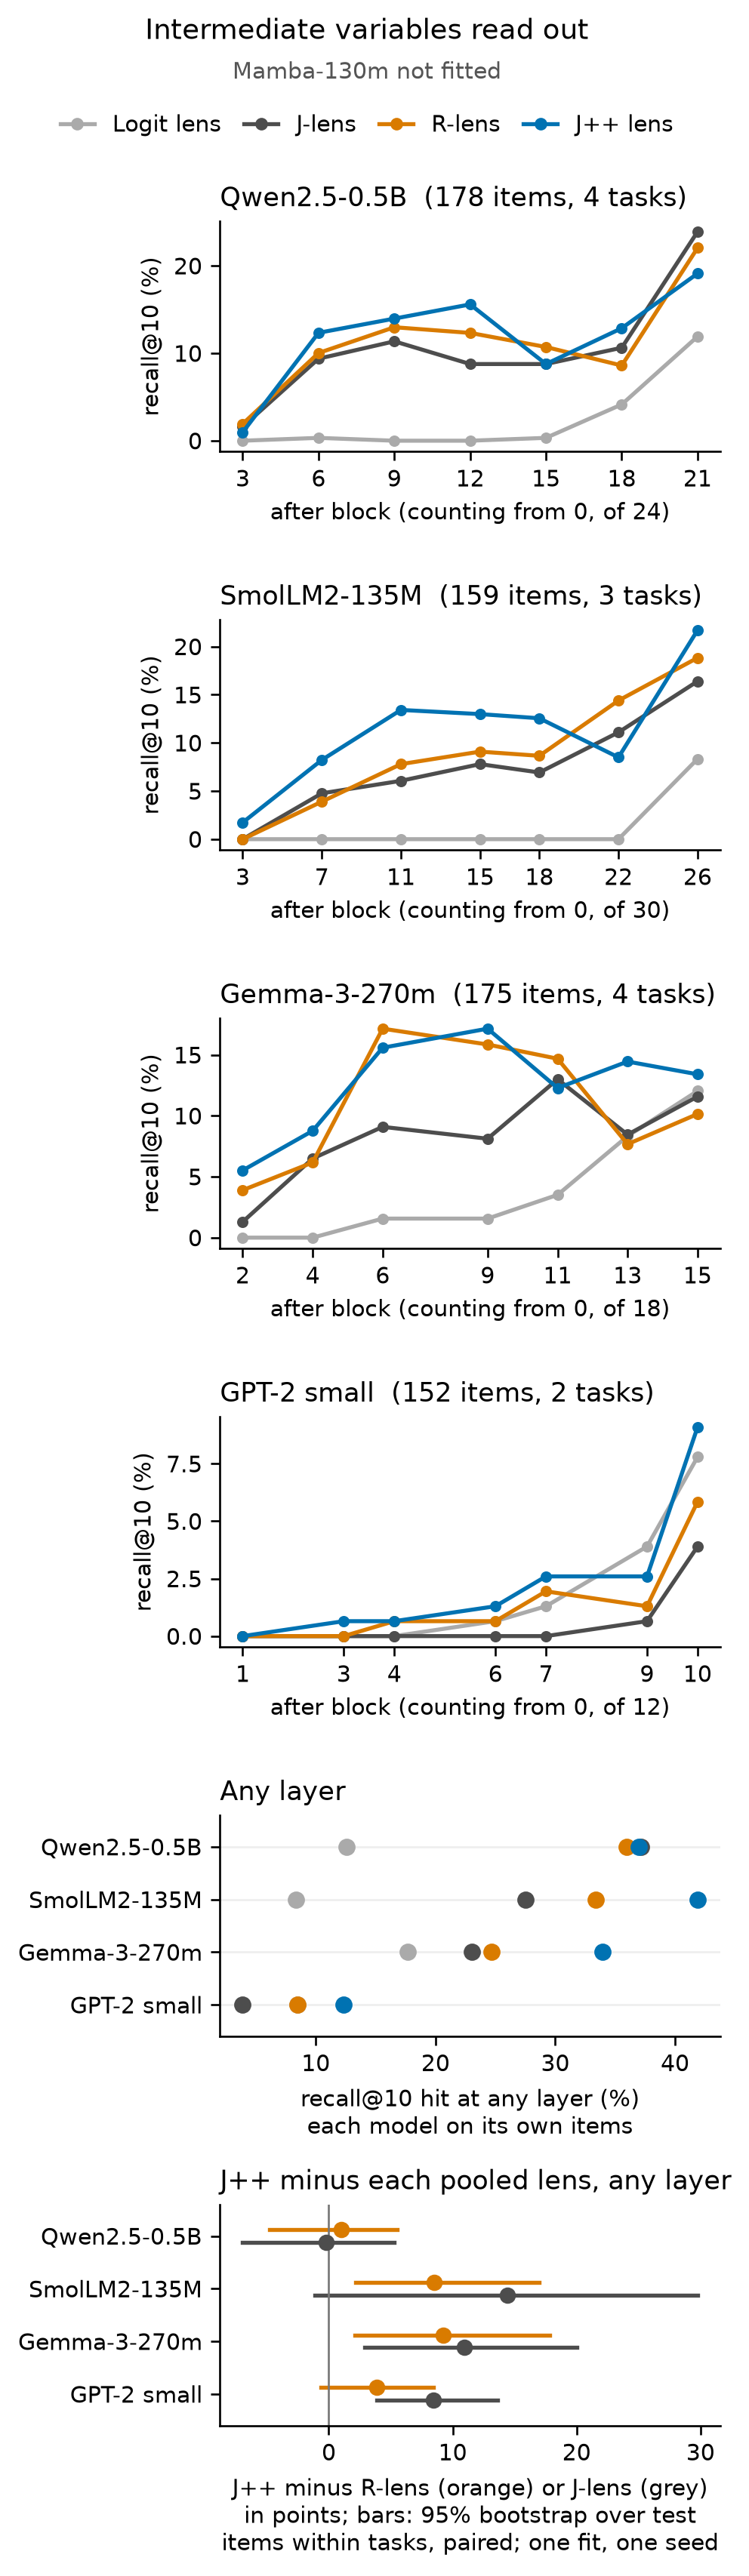

In [11]:
def figure_data(results):
    """The numbers the figure draws, per fitted model."""
    data = {}
    for name, r in results.items():
        H, test = r["H"], r["test"]
        data[name] = {
            "layers": r["layers"],
            "blocks": r["blocks"],
            "items": len(test),
            "tasks": len({it["task"] for it in test}),
            "per_layer": {
                lens: [100 * recall(h, test, layer=i) for i in range(len(r["layers"]))]
                for lens, h in H.items()
            },
            "any_layer": {lens: 100 * recall(h, test) for lens, h in H.items()},
            "paired": {
                o: tuple(100 * np.array(paired_difference(H["J++ lens"], H[o], test)))
                for o in ("R-lens", "J-lens")
            },
        }
    return data


def draw_results(data, not_fitted=()):
    """One column of panels, readable at phone width: recall per readout block, at any layer, and the paired J++ differences."""
    names, legend_in = (
        list(data),
        0.3 + 0.18 * bool(not_fitted),
    )  # inches from the top: title, note, then the legend
    top_in = (
        legend_in + 0.05
    )  # rect top for tight_layout, which adds its own pad above the first title
    fig_h = 2.15 * len(names) + 1.0 * len(names) + 1.1 + top_in
    fig = plt.figure(figsize=(4.2, fig_h), dpi=120)
    grid = fig.add_gridspec(
        len(names) + 2, 1, height_ratios=[1] * len(names) + [0.24 * len(names)] * 2
    )
    for k, name in enumerate(names):
        ax, d = fig.add_subplot(grid[k]), data[name]
        for lens, values in d["per_layer"].items():
            ax.plot(d["layers"], values, "o-", ms=3.5, lw=1.6, color=COLORS[lens], clip_on=False)
        ax.set_title(f"{name}  ({d['items']} items, {d['tasks']} tasks)", fontsize=10.5, loc="left")
        ax.set_xticks(d["layers"])
        ax.tick_params(labelsize=9)
        ax.set_xlabel(f"after block (counting from 0, of {d['blocks']})", fontsize=9)
        ax.set_ylabel("recall@10 (%)", fontsize=9)
        ax.set_ylim(-0.05 * ax.get_ylim()[1], ax.get_ylim()[1])  # zero sits above the axis line
        ax.spines[["top", "right"]].set_visible(False)
    y = np.arange(len(names))[::-1]
    ax = fig.add_subplot(grid[-2])  # every lens, hit at any layer
    for lens in COLORS:
        ax.scatter(
            [data[n]["any_layer"][lens] for n in names], y, color=COLORS[lens], s=34, zorder=3
        )
    ax.set_xlabel("recall@10 hit at any layer (%)\neach model on its own items", fontsize=9)
    ax.set_title("Any layer", fontsize=10.5, loc="left")
    ax.grid(axis="y", color="#EEEEEE")
    ax2 = fig.add_subplot(grid[-1])  # the paired comparison the text reports
    for k, other in enumerate(("R-lens", "J-lens")):
        for n, row in zip(names, y):
            point, low, high = data[n]["paired"][other]
            ax2.plot([low, high], [row + 0.12 - 0.24 * k] * 2, color=COLORS[other], lw=1.6)
            ax2.scatter(point, row + 0.12 - 0.24 * k, color=COLORS[other], s=30, zorder=3)
    ax2.axvline(0, color="#777777", lw=0.8)
    ax2.set_xlabel(
        "J++ minus R-lens (orange) or J-lens (grey)\n"
        "in points; bars: 95% bootstrap over test\nitems within tasks, paired; one fit, one seed",
        fontsize=9,
    )
    ax2.set_title("J++ minus each pooled lens, any layer", fontsize=10.5, loc="left")
    for a in (ax, ax2):
        a.set_yticks(y, names, fontsize=9)
        a.set_ylim(-0.6, len(names) - 0.4)
        a.tick_params(axis="x", labelsize=9)
        a.spines[["top", "right"]].set_visible(False)
    top = 1 - top_in / fig_h
    handles = [plt.Line2D([], [], color=c, marker="o", lw=1.6, ms=4) for c in COLORS.values()]
    fig.suptitle("Intermediate variables read out", fontsize=11, y=1 - 0.06 / fig_h, va="top")
    if not_fitted:
        fig.text(
            0.5,
            1 - 0.3 / fig_h,
            f"{', '.join(not_fitted)} not fitted",
            ha="center",
            va="top",
            fontsize=9,
            color="#555555",
        )
    fig.legend(
        handles,
        list(COLORS),
        loc="upper center",
        ncol=4,
        frameon=False,
        fontsize=9,
        bbox_to_anchor=(0.5, 1 - legend_in / fig_h),
        handlelength=1.5,
        columnspacing=1.0,
    )
    fig.tight_layout(rect=(0, 0, 1, top))
    return fig


draw_results(figure_data(results), [n for n in MODELS if n not in results])
plt.show()

## What the lenses read on one prompt

The first item of the typo task, "The course required that every student learn a second langauge", whose intermediate variable is "language". Each cell is a lens's top five tokens at the model's middle readout layer, with Readout Filtering. Typo items count for every model, since the task has no correctness filter.

In [12]:
item = next(it for t, it in RAW if t == "typo")
readout = {}
for name, r in results.items():
    m = Model(name)
    mid = len(m.layers) // 2
    ids = m.tok(item["prompt"], return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        h = first(tl.extract(m.model, ids, {"h": m.sources[mid]})["h"])[0, -1]
        lenses = {"Logit lens": None} | {lens: Jl[mid].to(DEVICE) for lens, Jl in r["J"].items()}
        row = {}
        for lens, Jl in lenses.items():
            logits = m.unembed(h if Jl is None else Jl @ h).masked_fill(
                r["nonsemantic"].to(DEVICE), float("-inf")
            )
            row[lens] = " | ".join(m.tok.decode(t).strip() for t in logits.topk(5).indices.tolist())
    readout[f"{name}, after block {m.layers[mid]}"] = row
    del m
    release()
display(pd.DataFrame(readout).T.style.set_properties(**{"text-align": "left"}))

,Logit lens,J-lens,R-lens,J++ lens
"Qwen2.5-0.5B, after block 12",Altern | Altern | altern | 是非 | 血脉,languages | language | langue | uese | spoken,langue | spoken | dialect | languages | uese,bilingual | /language | languages | lingu | language
"SmolLM2-135M, after block 15",and | in | of | or | for,english | languages | language | language | fluently,language | languages | or | to | and,language | languages | bilingual | fluently | spoken
"Gemma-3-270m, after block 9",ποιη | UAGES | itics | ystems | aughter,languages | languages | idioma | langue | dialects,languages | language | langue | Language | dialects,languages | language | langue | Language | lingua
"GPT-2 small, after block 6",and | from | style | for | ology,yip | veter | abwe | mathemat | ende,ge | ois | veter | abwe | mathemat,proficiency | Ace | skills | and | on


## Runtime

Wall time per model and stage in this run, and for the whole notebook.

In [13]:
display(
    pd.DataFrame(
        {name: {k: f"{v:.0f} s" for k, v in r["times"].items()} for name, r in results.items()}
    ).T
)
print(
    f"total wall time: {(time.time() - t_start) / 60:.1f} min on {torch.cuda.get_device_name(0) if GPU else 'CPU'}"
)

,routers,Jacobians,evals and J++ weights
Qwen2.5-0.5B,7 s,138 s,24 s
SmolLM2-135M,4 s,55 s,22 s
Gemma-3-270m,143 s,55 s,297 s
GPT-2 small,52 s,40 s,102 s


total wall time: 20.6 min on NVIDIA GeForce RTX 2080 Ti


## What this shows

**The rules port to these five implementations.** One rule list covered all five models at the tested library versions; Gemma 3 needed one more entry (GELU) and GPT-2 two (LayerNorm and its tanh GELU). Each edit passes its value and derivative check, and for every model the notebook asserts that the logits under the rules match the untraced model (largest relative change 3e-6, float32 round-off), that the gradient at the first readout layer does change (relative change 0.87 to 1.80), and that each rule edited the expected number of operations. On Mamba only the RMSNorm rule applies; its selective scan, convolution and gate keep the plain gradient, because the method gives no LRP rule for them and this notebook does not invent one. A new architecture still needs the same checks: its module names, fused operations or extra products can make a selector miss an operation or match the wrong one.

**The readout scores, at this scale.** This is one seed and a small fit: 8 sequences per model for the Jacobians (the post uses 64), 37 to 42 dev items for the J++ weights, and 152 to 178 test items over two to four tasks per model; 5 to 10 of each model's 56 expert Jacobians fell back to the pooled one. The models are scored on different item sets, so the numbers do not rank the models. Hit at any layer, the J++, R-lens and J-lens scores were 37.0, 36.0 and 37.2 on Qwen2.5-0.5B; 41.9, 33.4 and 27.5 on SmolLM2-135M; 33.9, 24.7 and 23.0 on Gemma-3-270m; and 12.3, 8.4 and 3.9 on GPT-2 small. In the paired comparison (second table), J++ minus the R-lens has an interval above zero on SmolLM2 (+8.5) and Gemma 3 (+9.2) and one that includes zero on Qwen2.5 (+1.0) and GPT-2 (+3.9); J++ minus the J-lens is above zero on Gemma 3 and GPT-2 and includes zero on Qwen2.5 and SmolLM2. These intervals cover only the resampling of test items for this one fit.

**Layer by layer.** J++ is not ahead at every layer: in the figure it falls below the R-lens at some layers of Qwen2.5, SmolLM2 and Gemma 3, most visibly at SmolLM2 layer 22. The J++ weights are chosen per layer to maximise dev recall macro-averaged over tasks, as in the released code, so with 37 to 42 dev items a task with a single dev item carries that task's whole share of the objective. In the earlier run on transformers 5.22, J++ fell to about 1% at Qwen2.5 layer 18 and SmolLM2 layer 22; a CPU rerun of that SmolLM2 fit found the chosen layer-22 weights hitting the one multihop dev item while hitting 16% of the 19 typo and none of the 18 association dev items. That is consistent with sensitivity to a tiny dev set, but it was not tested further (by dropping the item or enlarging the dev set).

**GPT-2 and Mamba.** GPT-2 small answers none of the multihop or multilingual items correctly, so only typo and association count, and all four lenses score low on it. Mamba-130m is not fitted here: its scan runs as plain PyTorch operations, so tracing and backward passes are slow (see the note above the fit), and the fit would take hours; set `FIT_MAMBA = True` to run it anyway.

**What TorchLens did.** The six rule entries become one recipe of `tl.when` clauses; module scoping is `tl.in_module`; the residual streams come from `tl.extract` and from `save_mode="view"` traces that keep autograd live; the drawings mark every edited operation without extra code; and the plain and LRP fits differ only in the `intervene=` argument.